# Lab 05 · A batch we can restart and explain

Automated Workflows in Satellite Image Processing · 5 November 2026

Lab 4 gave us one configured NDVI job. Lecture 5 asked whether its results were available, useful and explainable. Now we will run six requests and see what happens when one of them cannot finish.

By the end, you should be able to point to the expected work, explain an incomplete batch, recover it without losing history, and produce a report that another person can investigate.

The main exercise uses actual Sentinel-2 Collection 1 subsets from three dates near Kraków. Each date supplies two AOIs. The preserved inputs stay unchanged. Cloud screening comes later.

Core work: three new database tables, three logical repairs, two failure investigations, and a short decision. Allow about two hours. Coordinator interruption, missing outputs and the live acquisition route are extensions.

## 1. Open the package and inspect the evidence

Run the notebook from the Lab05 directory. Keep the supplied Python files beside it.

In [1]:
from pathlib import Path
import json, sqlite3, subprocess, sys
import numpy as np
import rasterio
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
assert (ROOT / 'lab05_cli.py').is_file(), 'Open the notebook from the extracted package directory.'

def cli(*args, expected=(0,)):
    child = subprocess.run([sys.executable, str(ROOT / 'lab05_cli.py'), *map(str, args)], capture_output=True, text=True)
    assert child.returncode in expected, (child.returncode, child.stdout[-2500:], child.stderr[-2500:])
    if child.returncode == 87:
        return {'exit_code': 87, 'note': 'The isolated coordinator stopped abruptly.'}
    return json.loads(child.stdout)

def check(group='all'):
    child = subprocess.run([sys.executable, str(ROOT / 'check_lab05.py'), group], capture_output=True, text=True)
    print(child.stdout)
    return child.returncode == 0

def query(manifest_path, sql, params=()):
    import batch_plan
    manifest = batch_plan.load(manifest_path)
    with sqlite3.connect(manifest['_database']) as connection:
        connection.row_factory = sqlite3.Row
        connection.execute('PRAGMA foreign_keys=ON')
        return [dict(row) for row in connection.execute(sql, params)]

print('Python', sys.version.split()[0], 'Rasterio', rasterio.__version__)
fixture = json.loads((ROOT / 'fixtures/manifest.json').read_text())
print('Endpoint:', fixture['endpoint'], 'Collection:', fixture['collection'])
print('Requests:', len(fixture['members']))

Python 3.13.9 Rasterio 1.4.4
Endpoint: https://earth-search.aws.element84.com/v1 Collection: sentinel-2-c1-l2a
Requests: 6


In [2]:
first_member = fixture['members'][0]
for role, entry in first_member['bands'].items():
    with rasterio.open(ROOT / 'fixtures' / entry['file']) as source:
        raw = source.read(1, masked=True)
        print(role, first_member['member_id'], source.shape, source.crs, source.scales, source.offsets, entry['sha256'])
        print('DN median:', float(np.ma.median(raw)))
print('Source transfer bytes:', sum(t['network_bytes'] for t in fixture['transfers']))

red S2A_T34UDA_20250604T094637_L2A-river (227, 219) EPSG:32634 (0.0001,) (-0.1,) ef3ca867df64c8b756ddd817d1ec25c6722f6e88a734863a63a95a9986abf684
DN median: 1778.0
nir S2A_T34UDA_20250604T094637_L2A-river (227, 219) EPSG:32634 (0.0001,) (-0.1,) e30bbf323834e7602031458e2b00f3d4b5e2ac06cd22a7967acf2032c78ec25c
DN median: 3441.0
Source transfer bytes: 12582918


Name one property a checksum establishes and one scientific question it cannot answer. Explain why six requests here represent three dates rather than six independent acquisitions.

Your explanation:

A checksum establishes that the file’s bytes are exactly the bytes recorded in the catalogue, so the file is intact and is the same object that was registered. It cannot answer a scientific question such as whether the pixels are free of cloud: a perfectly intact file can contain cloudy or otherwise unsuitable pixels, and the hash would be identical.

The six requests are three Sentinel-2 acquisitions (S2A on 4 June, S2C on 5 June and S2B on 10 June 2025, all tile T34UDA) times two AOIs (river and east). The two AOIs of one scene are windows cut from the same overpass, so they share the same sensing time, atmosphere, cloud situation and source files, and the live script reads those through one range session per scene and band. They are therefore two crops of one observation, not two independent acquisitions, and the source transfer in the manifest (about 12 MiB) covers three scenes, not six.

## 2. Design the new tables

Read `SCHEMA_CONTRACT.md`. Write all three tables in `student_batch_schema.sql`. The earlier acquisition and processing schemas are completed in `support/`.

Before writing SQL, sketch the links between a batch, its expected members, their requests, attempts and observations. Decide which records must exist when we know what we want but no calculation has started.

A member's planned request ID exists before its optional request foreign key can be filled. Explain why those are separate fields. Then run the schema check.

In [3]:
schema_ok = check('schema')

[
  {
    "check": "schema",
    "passed": true
  }
]



Your explanation:

Before any calculation starts, the catalogue must already hold the batch (batches, with the frozen manifest JSON) and every expected member (batch_members, each with its member_id, planned_request_id and spec_json). These rows record what we want to be done, so a member can be seen as expected even if no processing request, attempt or output exists. Observations in batch_observations are added later, and a member without any observation is reported as unobserved rather than disappearing. Requests, attempts, outputs and artifact locations belong to the processing side and appear only as work is registered and executed.

planned_request_id and request_id are separate because they answer different questions. planned_request_id is the scientific identity of the work (a fingerprint of the frozen specification), and it is known when the batch is frozen. request_id is a foreign key to processing_requests, and that row does not exist until the coordinator registers the request, so it must stay NULL until then. If the planned identity were itself a foreign key, we could not record expected work before the processing request exists. A CHECK constraint ties the two together: when request_id is filled it must equal planned_request_id, so the registered request is exactly the planned one. A UNIQUE constraint on (batch_id, planned_request_id) ensures one planned request appears only once in a batch.

## 3. Repair the coordination logic

The functions in `batch_repairs.py` execute, but the supplied versions make incorrect decisions. Read their contracts and repair them.

`classify_member` needs to distinguish blocked inputs, unresolved execution, verified completion and a permitted new attempt. A finished result may remain usable after its inputs move. An unresolved active execution needs attention even when an older result exists. The attempt budget does not reset when the coordinator restarts.

`verify_result` must reject evidence for another request, mismatching bytes, or missing verification. The adapter does the actual catalogue queries, hashing and raster inspection.

`summarize_batch` must count expected members once each using their newest observations. Repeated observations and joined locations do not create more requested work. Keep members that have no observation yet.

Predict which check will expose each supplied defect before editing.

In [4]:
for group in ('classify', 'verify', 'summary'):
    check(group)

[
  {
    "check": "classify",
    "passed": true
  }
]

[
  {
    "check": "verify",
    "passed": true
  }
]

[
  {
    "check": "summary",
    "passed": true
  }
]



Your explanation:

classify_member. The supplied version tests the attempt budget first and treats a missing input as a failure, so the classify check exposes it: the missing-input case returns failed instead of blocked. It also ignores validation_error and a failed last attempt (both would return ready), and a verified result with an exhausted budget or moved inputs would be reported as failed instead of complete. I reordered the decisions: active attempt (unresolved), verified result (complete), validation error (failed), missing input (blocked), exhausted budget counted across the catalogue (failed), ordinary failed attempt (failed, needs investigation), otherwise ready. An interrupted attempt returns to ready while budget remains.

verify_result. The verify check exposes it. The supplied function accepts any evidence that has an artifact_id, so evidence for another request, mismatching SHA256 or size, false verification flags, or a missing attempt ID would all pass. The repaired version requires an exact request_id match, non-empty attempt and artifact IDs, a positive recorded size equal to the measured size, equal recorded and measured SHA256, and True for the catalogue, grid and provenance flags. A missing field fails.

summarize_batch. The summary check exposes it. The supplied version counts every joined row, so a member with repeated observations is counted several times (the check reported 4 expected members instead of 3), and it skips members whose state is None, so unobserved work vanishes from the counts. The repaired version keeps only each member’s newest observation (largest observation ID), counts a missing observation as unobserved, and returns sorted member lists whose sizes add up to the expected membership.

## 4. Register expected work and run the batch

Finish the schema and function repairs before creating processing evidence. The next cell imports the captured real inputs into a fresh catalogue and freezes membership. It does not make a processing attempt.

Rerunning the notebook keeps existing work. To begin a separate experiment, choose a new workspace name.

In [5]:
assert check('all'), 'Finish the schema and three logical repairs first.'
MANIFEST = ROOT / 'work/batch.json'
if not MANIFEST.exists():
    print(cli('setup', '--directory', ROOT / 'work'))

expected_before = query(MANIFEST, 'SELECT member_id, planned_request_id, request_id FROM batch_members ORDER BY member_id')
expected_before

[
  {
    "check": "schema",
    "passed": true
  },
  {
    "check": "classify",
    "passed": true
  },
  {
    "check": "verify",
    "passed": true
  },
  {
    "check": "summary",
    "passed": true
  }
]



[{'member_id': 'S2A_T34UDA_20250604T094637_L2A-east',
  'planned_request_id': 'request-1f0182b0a73902beebff016cf6021e940743df028fd8608a90adc46773ab5135',
  'request_id': 'request-1f0182b0a73902beebff016cf6021e940743df028fd8608a90adc46773ab5135'},
 {'member_id': 'S2A_T34UDA_20250604T094637_L2A-river',
  'planned_request_id': 'request-8f013a06e81e7b70d60663f0b667b3ae88834e95473fbd7ce861ee1668ba8920',
  'request_id': 'request-8f013a06e81e7b70d60663f0b667b3ae88834e95473fbd7ce861ee1668ba8920'},
 {'member_id': 'S2B_T34UDA_20250610T095316_L2A-east',
  'planned_request_id': 'request-b5b1772ef1fc5ee4e9659d4665f1e1cb9f1bac8e378596e9862fbe26825fbc32',
  'request_id': 'request-b5b1772ef1fc5ee4e9659d4665f1e1cb9f1bac8e378596e9862fbe26825fbc32'},
 {'member_id': 'S2B_T34UDA_20250610T095316_L2A-river',
  'planned_request_id': 'request-370ad01517a0eadb95841e8be2230079802d4e27064f38d0aef42fb0c0a4acae',
  'request_id': 'request-370ad01517a0eadb95841e8be2230079802d4e27064f38d0aef42fb0c0a4acae'},
 {'member_

Write a query that lists expected members with no application attempt. Run it now. It should include the whole batch. Keep the query, its parameters and your interpretation in `investigation_queries.sql`.

In [6]:
no_attempt_sql = """
SELECT m.member_id, m.planned_request_id
FROM batch_members m
LEFT JOIN processing_attempts a ON a.request_id = m.planned_request_id
WHERE a.attempt_id IS NULL
ORDER BY m.member_id
"""
query(MANIFEST, no_attempt_sql)

[]

In [7]:
plan = cli('plan', '--manifest', MANIFEST)
print('Writes the database:', plan['writes_database'])
print([(m['member_id'], m['state'], m['reason']) for m in plan['members']])
result = cli('run', '--manifest', MANIFEST)
print('Complete:', result['complete'], 'New invocations:', len(result['invocations']))

Writes the database: False
[('S2A_T34UDA_20250604T094637_L2A-river', 'complete', 'Output verified'), ('S2A_T34UDA_20250604T094637_L2A-east', 'complete', 'Output verified'), ('S2C_T34UDA_20250605T095638_L2A-river', 'complete', 'Output verified'), ('S2C_T34UDA_20250605T095638_L2A-east', 'complete', 'Output verified'), ('S2B_T34UDA_20250610T095316_L2A-river', 'complete', 'Output verified'), ('S2B_T34UDA_20250610T095316_L2A-east', 'complete', 'Output verified')]
Complete: True New invocations: 0


Predict what a second invocation will change. Will it create another scientific product, another application attempt, or only new batch observations?

In [8]:
attempts_before = query(MANIFEST, 'SELECT COUNT(*) AS n FROM processing_attempts')[0]['n']
repeat = cli('run', '--manifest', MANIFEST)
attempts_after = query(MANIFEST, 'SELECT COUNT(*) AS n FROM processing_attempts')[0]['n']
print('New invocations:', len(repeat['invocations']))
assert repeat['complete'] and not repeat['invocations']
assert attempts_before == attempts_after

New invocations: 0


Your explanation:

Expected outcome. I expected the second invocation to create no new scientific product and no new application attempt, and to add only new batch observations. All six members were already complete with verified outputs, so the coordinator should only re-inspect them and record what it finds.

What happened. The second run launched nothing (New invocations: 0) and the number of rows in processing_attempts stayed the same, which the cell asserts. The plan already showed every member as complete with the reason “Output verified”, so classify_member never returned ready and the adapter was not called. This also means no attempt with status reused was created: the coordinator decides from verified evidence before any job starts, instead of launching the job and letting it discover that the result exists. What the second run did change is the batch record: for each member it appended new rows to batch_observations and refreshed the checked time of the file locations. Observations are append-only, so the earlier ones remain, and the report can distinguish when something was observed from when the report was generated. Completion is a re-verified claim (the adapter re-hashes the output file), not an old status read from the catalogue.

## 5. Look at the results and their report

A contact sheet makes the six results easy to compare. The saved raster values are not clipped. The display uses a fixed interval; blue and magenta identify values outside it.

Export a report, then open its HTML file. Follow one count to its members and inspect a request, producing attempt and verification time. Scientific cloud suitability should remain unassessed.

{'expected': 6, 'counts': {'ready': 0, 'complete': 6, 'blocked': 0, 'unresolved': 0, 'failed': 0, 'unobserved': 0}, 'members': {'ready': [], 'complete': ['S2A_T34UDA_20250604T094637_L2A-east', 'S2A_T34UDA_20250604T094637_L2A-river', 'S2B_T34UDA_20250610T095316_L2A-east', 'S2B_T34UDA_20250610T095316_L2A-river', 'S2C_T34UDA_20250605T095638_L2A-east', 'S2C_T34UDA_20250605T095638_L2A-river'], 'blocked': [], 'unresolved': [], 'failed': [], 'unobserved': []}}


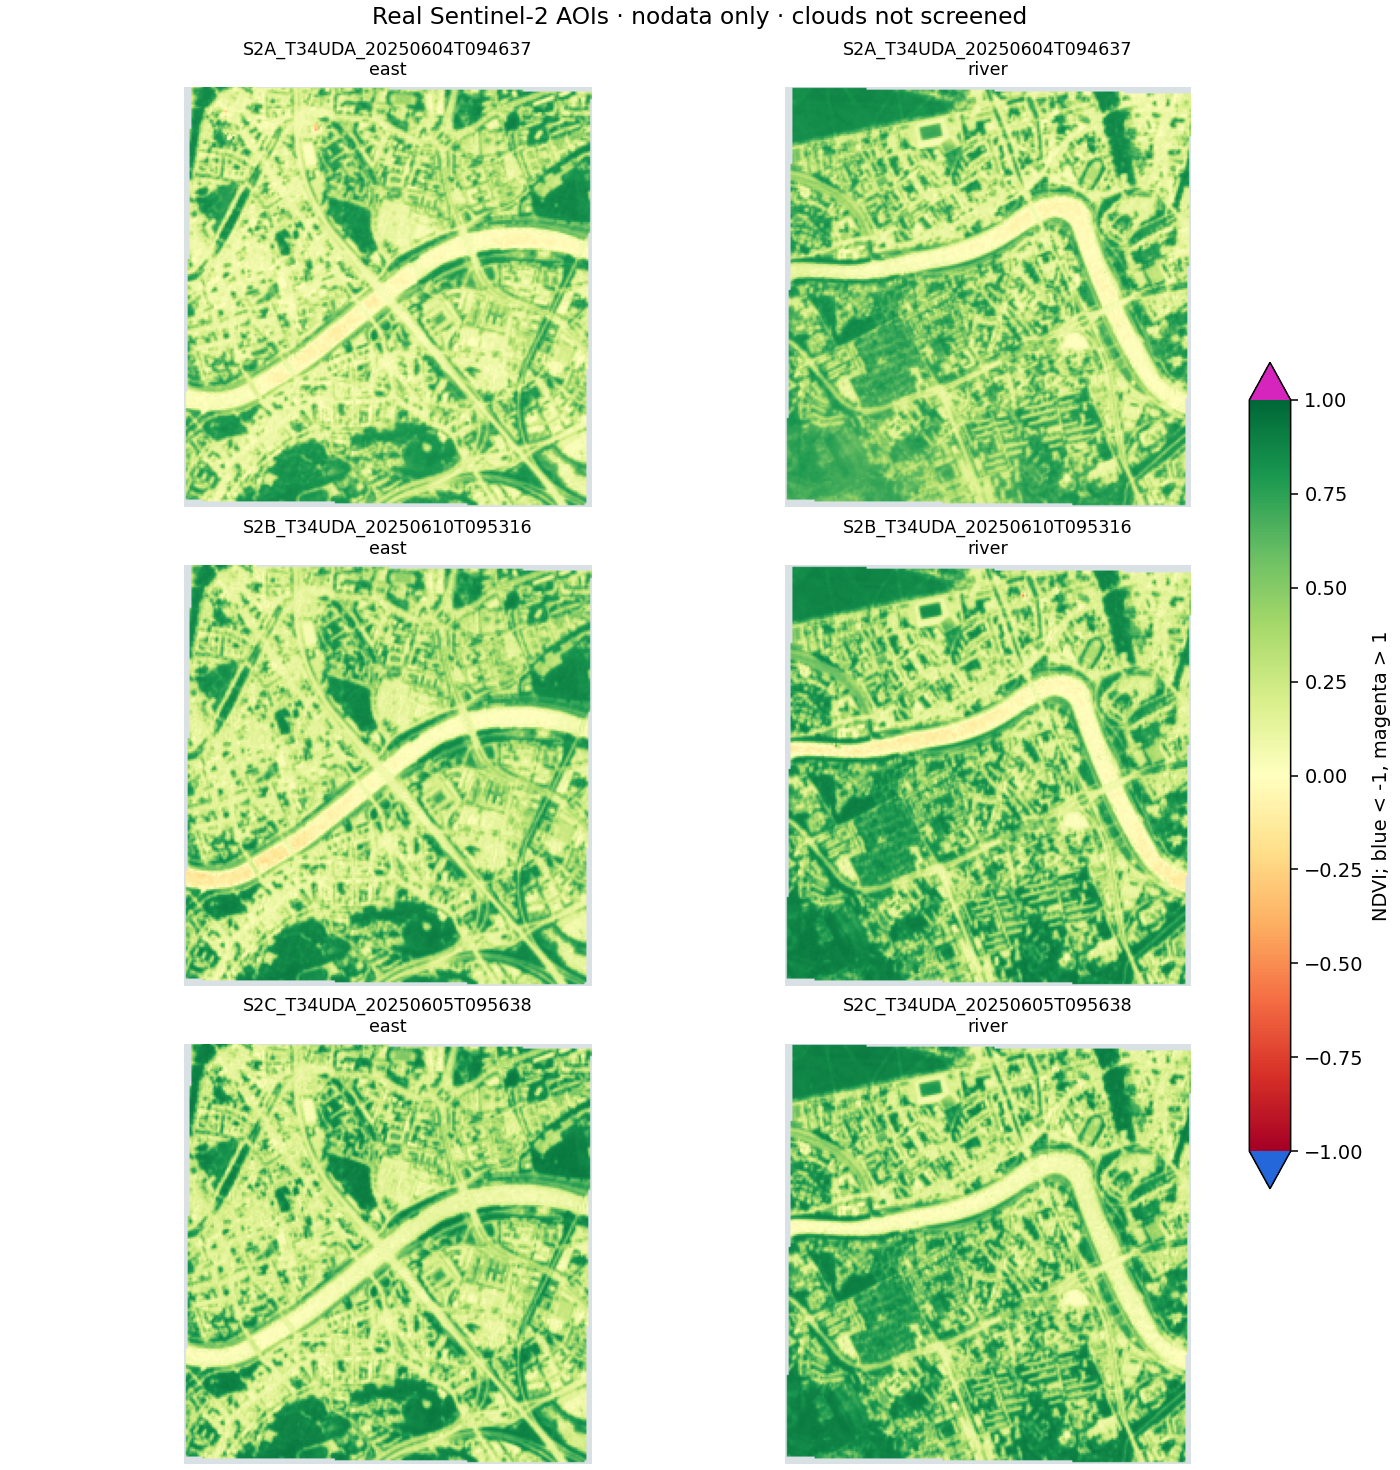

Open: C:\Users\mzawa\Desktop\mgr - II sem\Authomated_Workflows_Windows\Automated_Workflows\Labs\Lab05\reports\main\index.html


In [9]:
report_dir = ROOT / 'reports/main'
if not report_dir.exists():
    print(cli('report', '--manifest', MANIFEST, '--output', report_dir))
report = json.loads((report_dir / 'report.json').read_text())
print(report['summary'])
from IPython.display import Image, display
if (report_dir / 'preview.png').is_file():
    display(Image(filename=str(report_dir / 'preview.png')))
print('Open:', report_dir / 'index.html')

If the report says complete, what has it established? Give two reasons that still would not justify calling the image a clear sky vegetation observation. Identify the observation times separately from the report generation time.

Your explanation:

What “complete” establishes. For a member, complete means that at its observation time a succeeded producing attempt had an NDVI output whose bytes, grid and request/attempt tags were re-verified: the file exists, its SHA256 and size match the catalogue, it is linked to the exact planned request, and the raster passed the validation (finite-pixel coverage above the configured minimum). It is a statement about the processing record and the file, not about the scene. I followed the count of six complete members to S2A_T34UDA_20250604T094637_L2A-east, request request-1f0182b0…5135, produced by attempt attempt-7fd9ae93…eb8559 (output artifact output-6917f02b…a469), and read its verification detail in the report.

Why this is still not a clear-sky vegetation observation. (1) The mask policy is nodata_only and cloud suitability is explicitly “unassessed” (cloud_screened is False): no cloud, shadow or haze screening was applied, and clouds still give finite NDVI values (often close to zero), so finite coverage of over 96% says nothing about the sky being clear. (2) The validation checks that the arithmetic is valid, not that the surface is vegetation: a finite value inside the NDVI interval can come from water, bare ground, cloud shadow or an atmospheric effect. In addition, each result is a single acquisition of a small AOI, so seasonal state (phenology) is not assessed either.

Times. Three kinds of time must be kept apart. The scene was acquired on 4 June 2025 at about 09:46 UTC (from the Sentinel-2 item ID). The member was last observed at observed_at = 2026-11-10T21:33:16.97Z, which is when the coordinator checked the output file; the report gives its evidence age at export as 0.86 s. The report itself was generated at generated_at = 2026-11-10T21:33:17.83Z and its catalogue snapshot captured at 21:33:17.83Z. The report is a saved view of recorded observations: it does not re-check the files, so a file could change after observed_at unless refresh is run.

In [10]:
m = report['members'][0]       
print('member_id:      ', m['member_id'])
print('request_id:     ', m['request_id'])
print('attempt_id:     ', m['attempt_id'])
print('artifact_id:    ', m['evidence']['result']['artifact_id'])
print('observed_at:    ', m['observed_at'])
print('age at export:  ', m['age_seconds'], 'seconds')
print('generated_at:   ', report['generated_at'])
print('captured_at:    ', report['snapshot']['captured_at'])
print('cloud_screened: ', m['evidence']['result']['validation']['cloud_screened'])

member_id:       S2A_T34UDA_20250604T094637_L2A-east
request_id:      request-1f0182b0a73902beebff016cf6021e940743df028fd8608a90adc46773ab5135
attempt_id:      attempt-7fd9ae9317614168903c21c3afeb8559
artifact_id:     output-6917f02b4e064cadbb3939c4e2aa4cf8d32d4940c39d25c19bbae8910a81a469
observed_at:     2026-11-10T21:33:16.970973Z
age at export:   0.859678 seconds
generated_at:    2026-11-10T21:33:17.831723Z
captured_at:     2026-11-10T21:33:17.833735Z
cloud_screened:  False


## 6. Case A · One input disappears

The case helper creates a separate workspace, moves one red input aside, and runs the normal coordinator. Your main workspace and preserved fixtures stay intact.

Predict the expected member count, attempt count and number of completed requests. Then identify the exact blocked member and input role using SQL.

In [11]:
def ensure_case(name, directory, expected=(0, 1)):
    case_manifest = ROOT / directory / 'batch.json'
    if not case_manifest.exists():
        result = cli('case', '--name', name, '--directory', ROOT / directory, expected=expected)
        print('Created:', name, result.get('manifest', result.get('note')))
    return case_manifest

missing = ensure_case('missing-input', 'cases/missing')
query(missing, """SELECT m.member_id, o.state, o.reason, o.observed_at
FROM batch_members m JOIN batch_observations o USING(batch_id,member_id)
WHERE o.observation_id=(SELECT MAX(x.observation_id) FROM batch_observations x
WHERE x.batch_id=m.batch_id AND x.member_id=m.member_id)
ORDER BY m.member_id""")

[{'member_id': 'S2A_T34UDA_20250604T094637_L2A-east',
  'state': 'complete',
  'reason': 'Output verified',
  'observed_at': '2026-11-10T21:34:01.187297Z'},
 {'member_id': 'S2A_T34UDA_20250604T094637_L2A-river',
  'state': 'complete',
  'reason': 'Output verified',
  'observed_at': '2026-11-10T21:34:01.169952Z'},
 {'member_id': 'S2B_T34UDA_20250610T095316_L2A-east',
  'state': 'complete',
  'reason': 'Output verified',
  'observed_at': '2026-11-10T21:34:01.260503Z'},
 {'member_id': 'S2B_T34UDA_20250610T095316_L2A-river',
  'state': 'complete',
  'reason': 'Output verified',
  'observed_at': '2026-11-10T21:34:01.242395Z'},
 {'member_id': 'S2C_T34UDA_20250605T095638_L2A-east',
  'state': 'complete',
  'reason': 'Output verified',
  'observed_at': '2026-11-10T21:34:01.222234Z'},
 {'member_id': 'S2C_T34UDA_20250605T095638_L2A-river',
  'state': 'complete',
  'reason': 'Output verified',
  'observed_at': '2026-11-10T21:34:01.204569Z'}]

In [12]:
query(missing, """SELECT a.artifact_id, json_extract(a.lineage_json,'$.asset_key') AS role,
 l.status, l.local_path, l.checked_at
FROM processing_artifacts a JOIN processing_artifact_locations l USING(artifact_id)
WHERE a.source_artifact_id IS NOT NULL AND l.status <> 'available'""")

[]

Explain why the blocked member has no failed application attempt. How does expected membership let us see work that never started? Add the query that established your diagnosis to your query file.

Your explanation:

Expected outcome. Six expected members; five application attempts and five completed requests, because only the first member’s red input was moved aside and every other member has its own inputs.

Diagnosis. Using the append-only batch_observations (query 5 in my query file), the blocked member is S2A_T34UDA_20250604T094637_L2A-river and the missing role is red (cases\missing\inputs\S2A_T34UDA_20250604T094637_L2A-river-red.tif). Its blocked observation has attempts_before_observation = 0: no attempt for this request had started.

Why there is no failed attempt. The coordinator never launched the job. The adapter found that a required input had no available location, classify_member returned blocked, and a blocked input uses no attempt, so the attempt budget was not touched. A failed attempt would mean the job actually ran and failed, which is a different situation that needs a different response.

Why expected membership matters. batch_members was filled when the batch was frozen, so the sixth request existed in the catalogue before any attempt did. A LEFT JOIN from members to attempts exposes it as work with zero attempts. Looking only at processing_attempts would show five succeeded attempts and no sign that anything was missing. After the input was restored and the batch run again, the sixth attempt succeeded (six succeeded attempts in total), and the earlier blocked observations remain as history.

In [13]:
note = json.loads((missing.parent / 'case_note.json').read_text())
if Path(note['held']).exists() and not Path(note['original']).exists():
    print(cli('restore-input', '--manifest', missing))
recovered = cli('run', '--manifest', missing)
print('Complete after restoration:', recovered['complete'])
query(missing, 'SELECT status, COUNT(*) AS n FROM processing_attempts GROUP BY status')

Complete after restoration: True


[{'status': 'succeeded', 'n': 6}]

## 7. Case B · The worker stops before publication

This helper waits for the actual child process to stop with exit code 86. The child wrote and validated a temporary raster, then exited without running cleanup. Its attempt still says running.

Predict what the coordinator will do with the remaining requests. We still permit only one active processing invocation per catalogue.

In [14]:
worker = ensure_case('interrupted-worker', 'cases/worker')
query(worker, 'SELECT attempt_id, request_id, status, stage, temp_path, final_path FROM processing_attempts ORDER BY started_at')

[{'attempt_id': 'attempt-733022cf43b844f28b24233a0f4fe8d7',
  'request_id': 'request-8f013a06e81e7b70d60663f0b667b3ae88834e95473fbd7ce861ee1668ba8920',
  'status': 'interrupted',
  'stage': 'before_rename',
  'temp_path': 'C:\\Users\\mzawa\\Desktop\\mgr - II sem\\Authomated_Workflows_Windows\\Automated_Workflows\\Labs\\Lab05\\cases\\worker\\outputs\\.attempt-733022cf43b844f28b24233a0f4fe8d7.partial.tif',
  'final_path': 'C:\\Users\\mzawa\\Desktop\\mgr - II sem\\Authomated_Workflows_Windows\\Automated_Workflows\\Labs\\Lab05\\cases\\worker\\outputs\\attempt-733022cf43b844f28b24233a0f4fe8d7.ndvi.tif'},
 {'attempt_id': 'attempt-93a4a0a692d646deb9158201b16b6dd4',
  'request_id': 'request-8f013a06e81e7b70d60663f0b667b3ae88834e95473fbd7ce861ee1668ba8920',
  'status': 'succeeded',
  'stage': 'complete',
  'temp_path': 'C:\\Users\\mzawa\\Desktop\\mgr - II sem\\Authomated_Workflows_Windows\\Automated_Workflows\\Labs\\Lab05\\cases\\worker\\outputs\\.attempt-93a4a0a692d646deb9158201b16b6dd4.partia

Use SQL and file inspection to distinguish an interrupted execution from a missing input. Record why it is justified to assert that this child stopped. In a real unattended system, a timestamp alone would not establish that.

In [15]:
running = query(worker, "SELECT attempt_id, temp_path, final_path FROM processing_attempts WHERE status='running'")
for row in running:
    print(row['attempt_id'], 'temporary:', Path(row['temp_path']).exists(), 'final:', Path(row['final_path']).exists())
print('Output links:', query(worker, 'SELECT COUNT(*) AS n FROM processing_outputs'))

Output links: [{'n': 6}]


Your explanation:

Expected outcome. The first member’s worker stops with exit code 86 after writing a temporary raster, leaving its attempt running. The coordinator allows only one active processing invocation per catalogue, so the remaining members are classified as blocked (“catalogue has an unresolved execution”) and are not launched. Nothing is published, so there are no output links.

Interrupted versus missing input. A missing input has no attempt at all and a missing location for an input artifact. Here attempt attempt-733022cf… exists for request request-8f013a06… (member S2A_T34UDA_20250604T094637_L2A-river). Its log shows the stages validate_inputs and before_rename, its input locations are available, and no processing_outputs row links an output to it. The temporary raster (161,723 bytes) was preserved in outputs\quarantine when the attempt was reconciled. So the work started and was cut off before publication; it was not prevented from starting.

Why asserting that the child stopped is justified. The case helper waited for the actual child process and observed its exit code (86) before the next step, and the coordinator runs serially under an exclusive lock, so no other process could still be writing this attempt. A timestamp would not establish this: the interrupted event in the log (21:33:29.07) records when reconcile ran, about 0.9 s after the last worker event (21:33:28.18), not when the process stopped. In a real unattended system I would need process liveness, a heartbeat, or the scheduler’s own record that the job ended. --confirm-stopped only records my assertion; it does not prove it.

After reconcile. The attempt became interrupted (PROCESS_STOPPED_BEFORE_PUBLISH), which is within the budget of two attempts, so the request returned to ready. The next run created attempt attempt-93a4a0a6…, which succeeded and published the output.

Recovery query (cell 36). The query returns request request-8f013a06… with the earlier interrupted attempt attempt-733022cf… and the later producing attempt attempt-93a4a0a6…. Counting attempts would overstate delivered work: this request has two attempts but only one product. Delivered work is counted as verified outputs per request, not as attempts.

In [16]:
for row in running:
    print(cli('reconcile', '--manifest', worker, '--attempt-id', row['attempt_id'], '--confirm-stopped'))
worker_recovered = cli('run', '--manifest', worker)
assert worker_recovered['complete']
query(worker, 'SELECT request_id, status, error_code, started_at FROM processing_attempts ORDER BY started_at')

[{'request_id': 'request-8f013a06e81e7b70d60663f0b667b3ae88834e95473fbd7ce861ee1668ba8920',
  'status': 'interrupted',
  'error_code': 'PROCESS_STOPPED_BEFORE_PUBLISH',
  'started_at': '2026-11-10T21:33:28.051243Z'},
 {'request_id': 'request-8f013a06e81e7b70d60663f0b667b3ae88834e95473fbd7ce861ee1668ba8920',
  'status': 'succeeded',
  'error_code': None,
  'started_at': '2026-11-10T21:33:29.952096Z'},
 {'request_id': 'request-1f0182b0a73902beebff016cf6021e940743df028fd8608a90adc46773ab5135',
  'status': 'succeeded',
  'error_code': None,
  'started_at': '2026-11-10T21:33:30.565443Z'},
 {'request_id': 'request-81041d52787fff61cd5e976005eb7e89fbad02ca29656829d6a01c72baa88e7c',
  'status': 'succeeded',
  'error_code': None,
  'started_at': '2026-11-10T21:33:31.164221Z'},
 {'request_id': 'request-b7a3a23dd4ad56e1618dc9c96d87cbf43cc1139c323e19587f0ab53d774b363f',
  'status': 'succeeded',
  'error_code': None,
  'started_at': '2026-11-10T21:33:31.753789Z'},
 {'request_id': 'request-370ad01517

Write a query that finds a request with an interrupted or failed attempt and a later producing attempt. Show both identities. Explain why counting attempts would overstate delivered work.

In [17]:
import batch_plan

recovery_sql = """
SELECT m.member_id, m.planned_request_id AS request_id,
       bad.attempt_id AS earlier_attempt_id, bad.status AS earlier_status,
       bad.error_code AS earlier_error_code,
       good.attempt_id AS producing_attempt_id, o.artifact_id
FROM batch_members m
JOIN processing_attempts bad ON bad.request_id = m.planned_request_id
                            AND bad.status IN ('failed','interrupted')
JOIN processing_attempts good ON good.request_id = bad.request_id
                             AND good.status = 'succeeded'
                             AND (good.started_at > bad.started_at
                                  OR (good.started_at = bad.started_at AND good.attempt_id > bad.attempt_id))
JOIN processing_outputs o ON o.attempt_id = good.attempt_id AND o.role = 'ndvi'
WHERE m.batch_id = :batch_id
ORDER BY m.member_id, bad.started_at
"""
query(worker, recovery_sql, {'batch_id': batch_plan.load(worker)['batch_id']})

[{'member_id': 'S2A_T34UDA_20250604T094637_L2A-river',
  'request_id': 'request-8f013a06e81e7b70d60663f0b667b3ae88834e95473fbd7ce861ee1668ba8920',
  'earlier_attempt_id': 'attempt-733022cf43b844f28b24233a0f4fe8d7',
  'earlier_status': 'interrupted',
  'earlier_error_code': 'PROCESS_STOPPED_BEFORE_PUBLISH',
  'producing_attempt_id': 'attempt-93a4a0a692d646deb9158201b16b6dd4',
  'artifact_id': 'output-9005e6cd400906cb806b8c25f9923d545a49a5dd305ed6084c269fd7f460a0a0'}]

In [18]:
query(missing, """SELECT observation_id, member_id, state, reason,
  json_extract(evidence_json,'$.context.missing_inputs') AS missing_inputs
FROM batch_observations WHERE state='blocked' ORDER BY observation_id""")

[{'observation_id': 1,
  'member_id': 'S2A_T34UDA_20250604T094637_L2A-river',
  'state': 'blocked',
  'reason': 'Input unavailable: red',
  'missing_inputs': '["red"]'},
 {'observation_id': 12,
  'member_id': 'S2A_T34UDA_20250604T094637_L2A-river',
  'state': 'blocked',
  'reason': 'Input unavailable: red',
  'missing_inputs': '["red"]'}]

In [19]:
attempt = 'attempt-733022cf43b844f28b24233a0f4fe8d7'
quarantined = worker.parent / 'outputs' / 'quarantine' / f'{attempt}.partial.tif'
print('quarantined temp file exists:', quarantined.is_file())
if quarantined.is_file():
    print('size:', quarantined.stat().st_size, 'bytes')

log = worker.parent / 'logs' / f'{attempt}.jsonl'
print(log.read_text())

quarantined temp file exists: True
size: 161723 bytes
{"attempt_id":"attempt-733022cf43b844f28b24233a0f4fe8d7","request_id":"request-8f013a06e81e7b70d60663f0b667b3ae88834e95473fbd7ce861ee1668ba8920","stage":"validate_inputs","status":"running","time":"2026-11-10T21:33:28.061034Z"}
{"attempt_id":"attempt-733022cf43b844f28b24233a0f4fe8d7","sha256":"d2a7459738a7f13f5a13dc5d4763b50e947b5b8c650253c82e72a39d0aa8c135","stage":"before_rename","time":"2026-11-10T21:33:28.177233Z"}
{"attempt_id":"attempt-733022cf43b844f28b24233a0f4fe8d7","status":"interrupted","time":"2026-11-10T21:33:29.069315Z"}



## 8. A decision another person can follow

It is Saturday morning. One member is blocked because an input file is missing. Five other members have verified outputs. Delivery is required on Monday afternoon.

Write a short note stating what is known, what remains uncertain, the next check, and whether you would act now or defer. Explain how your decision changes if an incorrect calibration may have affected already published products.

Save your useful SQL with a question, parameters, empty-result interpretation and next action. Sketch one overview and one detail view using the fields you actually have. Mark any proposed future measurements as unavailable rather than inventing them.

Your explanation:

Decision note (Saturday morning).

Known. Five members are complete: at their observation times, each had a succeeded producing attempt and an NDVI output whose bytes (SHA256, size), grid and request/attempt tags were re-verified. One member (S2A_T34UDA_20250604T094637_L2A-river in my exercise case) is blocked because its red input has no available location. Blocked means the job never started: no application attempt was created and the budget of two attempts per request is untouched. These statements describe the catalogue at the recorded observed_at times, not the filesystem now.

Uncertain. (1) Whether the input file is really gone or only moved: the catalogue lists no available copy, which is a past check. (2) Whether a verified copy with the same SHA256 exists elsewhere. (3) Whether the five outputs are still intact now, since they were last checked at their observed_at. (4) Scientific suitability of all six: cloud suitability is unassessed and the mask is nodata_only, so “complete” does not mean clear sky.

Next check. Run refresh, which performs current file checks and appends observations without launching any job. Then query the location checks for the blocked input (my query 5) and look for a copy whose SHA256 matches the registered artifact.

Decision: act now on diagnosis and recovery, but only through verified evidence. refresh is cheap, appends history and does not change any scientific result, and Saturday leaves time before Monday afternoon. If a copy with the registered SHA256 exists, I restore it and run the batch; only the sixth request launches, and the five verified products are reused. If no verified copy exists, I do not substitute another scene or regenerate by changing settings. I would use the explicit live acquisition into a new destination, check that the source and bytes match the registered input, and register a new manifest if the input identity differs (a changed input is a new scientific request, not an edit). If that fails too, I deliver the five verified members on Monday with the sixth clearly marked as missing and the reason recorded, and I state that cloud suitability is unassessed for all of them.

If an incorrect calibration may have affected products already published. The decision changes completely. A verified checksum proves that the bytes are the bytes we produced, not that the scale and offset were right, and the calibration is part of each request’s frozen settings, so all six requests (including the five “complete” ones) would carry the same defect. Recovering the blocked member would then be secondary and I would not run it with the same settings. I would first identify which requests used the suspect calibration (from the frozen spec_json), hold or flag delivery of the affected products, keep the old products and their history unchanged, and freeze a new manifest with the corrected calibration, which creates new request identities and new attempts within the budget. Then I would tell the recipients which published products are affected. The Monday deadline would be met either with corrected products or with an explicit statement of what is withdrawn and why.

Saved SQL. The queries with question, parameters, columns, empty-result interpretation and next action are in investigation_queries.sql.

Overview view (fields I have). One row per member: member_id, newest state, reason, observed_at, age_seconds (evidence age at export), next_check; above it, the six counts (ready, complete, blocked, unresolved, failed, unobserved) as links to the member lists.

Detail view (fields I have). For one member: planned_request_id and request_id; the attempts for it (attempt_id, status, error_code, started_at); the producing artifact_id, sha256, size_bytes; the finite NDVI coverage (valid_pixels / total_pixels); the location checks (path, status, checked_at); the full list of earlier observations.

Unavailable (proposed future measurements, not invented). AOI-level cloud or shadow fraction and a cloud suitability flag; a quality-band screening result; an independent validation of the calibration; the age or presence of an unattended-job heartbeat. The catalogue stores only the scene-level eo:cloud_cover from the item, which is not a statement about the AOI.

## Extensions

1. Create `interrupted-coordinator` in a new case directory. The command exits with code 87 after one completed member. Run the same manifest again and prove that only five jobs launch.
2. Create `missing-output`. Inspect both the old succeeded attempt and the new location observations. Recover the output without rewriting history.
3. Add a second copy of a verified output, then remove one copy. Explain why a query using any missing location gives the wrong answer.
4. Repeat the explicit live acquisition command from `README.md` into a new directory. Compare its captured source metadata and subset hashes with the supplied manifest.
5. Change a scientific setting in one configuration and freeze a new manifest. Contrast that new request with a change to an output directory.

Keep extensions separate from your core evidence. Never remove old attempt rows to make a report look clean.

## Submit

Keep your notebook, three table definitions, three repairs, query file, one saved report, and the decision note. Include the failed/interrupted evidence as well as the recovered outcome.

The extensions are optional.